In [12]:
# Updating package with new changes
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck b at (4, 7, 0)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Unassigned
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Unassigned

Final State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck a at (0, 5, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Truck a at (0, 5, 2)
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck b at (4, 7, 0)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (0, 0, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck a at (0, 5, 1)

Final Objective Value: 250
Runtime: 2.2321821960003945 sec
Iterations: 5


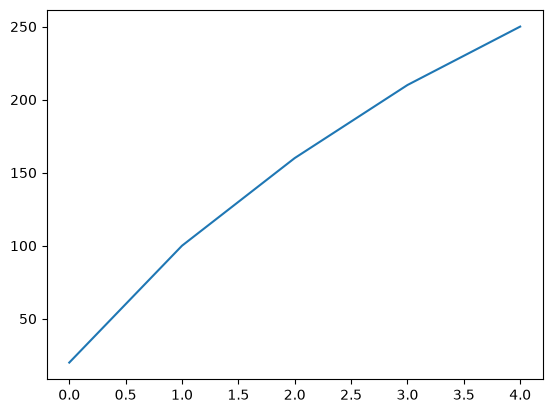

In [19]:
# Trying Steepest Ascent Hill Climbing
from src.engine import *
from src.solvers.hill_climbing import SteepestAscent
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Steepest Ascent Hill Climbing
solver_steepest_ascent = SteepestAscent(obj, max_iterations = 100)
results_steepest_ascent = solver_steepest_ascent.solve(initial_state)

# Getting the results
print("Final State:", results_steepest_ascent.final_state) # Output: Final State
print("Final Objective Value:", results_steepest_ascent.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_steepest_ascent.runtime, "sec") # Output: Runtime
print("Iterations:", results_steepest_ascent.total_iterations) # Output: Iterations
plt.plot(results_steepest_ascent.objective_history) # Output: Plot of Objective Value over Iterations

Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck b at (3, 8, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck a at (1, 15, 0)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Unassigned
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Unassigned

Final State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck b at (3, 8, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Truck a at (0, 5, 1)
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Truck a at (1, 15, 0)
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (0, 0, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck a at (0, 5, 0)

Final Objective Value: 250
Runtime: 29.314086315000168 sec
Iterations: 54
Total Sideways

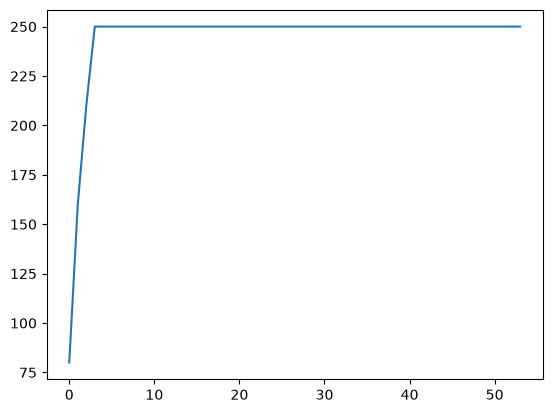

In [20]:
# Trying Sideways Move Hill Climbing
from src.engine import *
from src.solvers.hill_climbing import SidewaysMove
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_sideways_move = SidewaysMove(obj, max_sideways_moves = 50, max_iterations = 100)
results_sideways_move = solver_sideways_move.solve(initial_state)

# Getting the results
print("Final State:", results_sideways_move.final_state) # Output: Final State
print("Final Objective Value:", results_sideways_move.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_sideways_move.runtime, "sec") # Output: Runtime
print("Iterations:", results_sideways_move.total_iterations) # Output: Iterations
print("Total Sideways Moves:", results_sideways_move.metadata["sideways_moves"]) # Output: Total Sideways Moves
plt.plot(results_sideways_move.objective_history) # Output: Plot of Objective Value over Iterations

Initial State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Truck a at (5, 17, 0)
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Unassigned
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (4, 9, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck b at (5, 1, 0)

Final State: State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck a at (5, 17, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Unassigned
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (4, 9, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Truck b at (5, 1, 0)

Final Objective Value: 190
Runtime: 0.0005435169996417244 sec
Iterations: 22
Random Successor Iter

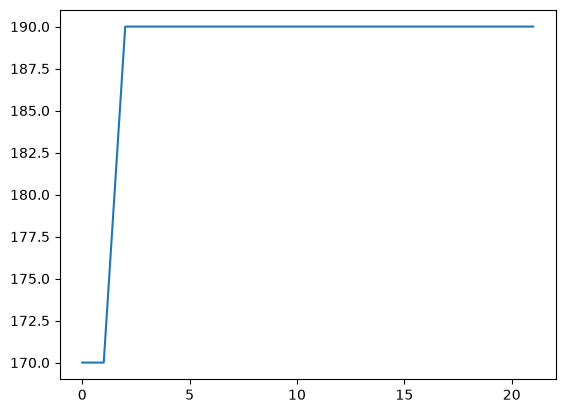

In [17]:
# Trying Stochastic Hill Climbing
from src.engine import *
from src.solvers.hill_climbing import Stochastic
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")
print("Initial State:",initial_state) # Output: Initial State

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_stochastic = Stochastic(obj, max_random_successor_iterations=20, max_iterations = 100)
results_stochastic = solver_stochastic.solve(initial_state)

# Getting the results
print("Final State:", results_stochastic.final_state) # Output: Final State
print("Final Objective Value:", results_stochastic.objective_history[-1]) # Output: Final Objective Value
print("Runtime:", results_stochastic.runtime, "sec") # Output: Runtime
print("Iterations:", results_stochastic.total_iterations) # Output: Iterations
print("Random Successor Iterations:", results_stochastic.metadata["random_successor_iterations"]) # Output: Random Successor Iterations
plt.plot(results_stochastic.objective_history) # Output: Plot of Objective Value over Iterations

Initial States: [State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Unassigned
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Unassigned
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Unassigned
, State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Unassigned
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, eta=1) -> Unassigned
  Package C (dim=1x1x1, weight=1, value=20, fragile=False, eta=2) -> Unassigned
  Package D (dim=4x5x2, weight=7, value=80, fragile=True, eta=4) -> Truck a at (1, 14, 0)
  Package E (dim=2x3x1, weight=4, value=50, fragile=False, eta=5) -> Unassigned
, State:
  Package A (dim=3x4x1, weight=5, value=60, fragile=False, eta=3) -> Truck a at (4, 11, 0)
  Package B (dim=2x2x2, weight=3, value=40, fragile=True, et

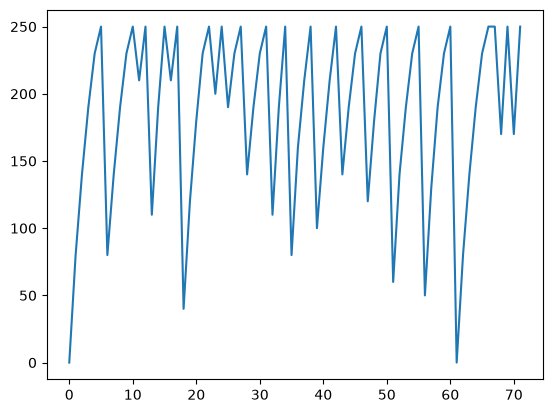

In [18]:
# Trying Random Restart Hill Climbing
from src.engine import *
from src.solvers.hill_climbing import RandomRestart
import matplotlib.pyplot as plt


# Input packages and trucks
pkgs = [
   # Package(id, width, length, height, value, weight, is_fragile, eta) 
   Package("A", 3, 4, 1, 60, 5, False, 3), 
   Package("B", 2, 2, 2, 40, 3, True, 1),
   Package("C", 1, 1, 1, 20, 1, False, 2),
   Package("D", 4, 5, 2, 80, 7, True, 4),
   Package("E", 2, 3, 1, 50, 4, False, 5)
]
# Truck(id, width, length, height, max_capacity)
trucks = [Truck("a", 10, 20, 5, 25), Truck("b", 8, 15, 4, 30)]

# Set Initial State
initial_state = State(pkgs, trucks, init="random_feasible")

# Set up requirements for hill climbing
obj = MaxValueObjective()

# Executing Sideways Move Hill Climbing
solver_random_restart = RandomRestart(obj, max_restarts=20, max_iterations_per_restart=100, initial_state=initial_state)
results_random_restart = solver_random_restart.solve()

# Getting the results
print("Initial States:", results_random_restart.initial_state) # Input: List of Random Initial States
print("Final State:", results_random_restart.final_state) # Output: Final State
print("Final Objective Value:", results_random_restart.metadata["final_objective_value"]) # Output: Final Objective Value
print("Runtime:", results_random_restart.runtime, "sec") # Output: Runtime
print("Total Restarts:", results_random_restart.metadata["total_restarts"]) # Output: Total Restarts
print("Iterations per Restart:", results_random_restart.metadata["iterations_per_restart"]) # Output: Iterations
plt.plot(results_random_restart.objective_history) # Output: Plot of Objective Value over Iterations